# 03 · Feature Interaction

1. **Feature × Feature**: tương quan giữa các biến số liên tục.
2. **Feature × Treatment**: uplift thực sự theo từng phân khúc (randomized treatment nên so sánh trực tiếp hai nhánh):
   - `uplift_cash = P(cash_sign_30d=1 | Cash) − P(cash_sign_30d=1 | Card)`
   - `uplift_card = P(card_sign_30d=1 | Card) − P(card_sign_30d=1 | Cash)`

   Mức độ tương tác của một feature với treatment được đo bằng độ lệch chuẩn có trọng số của uplift giữa các bin (`*_wstd`, đơn vị điểm %), chỉ giữ bin có ≥ 200 khách ở mỗi nhánh.
3. **Ma trận tương tác cho INT_RF**: `[X, W, X·W]`.

In [1]:
import sys
sys.path.append("..")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from src import config as C
from src.analysis import add_buckets, interaction_strength, segment_uplift, strong_correlations
from src.models import interaction_matrix
from src.preprocessing import load_model_data

df = add_buckets(pd.read_csv(C.TRAIN_CLEANED))
FIG = C.FIGURES_DIR
plt.rcParams["figure.dpi"] = 72

## 1. Feature × Feature correlation

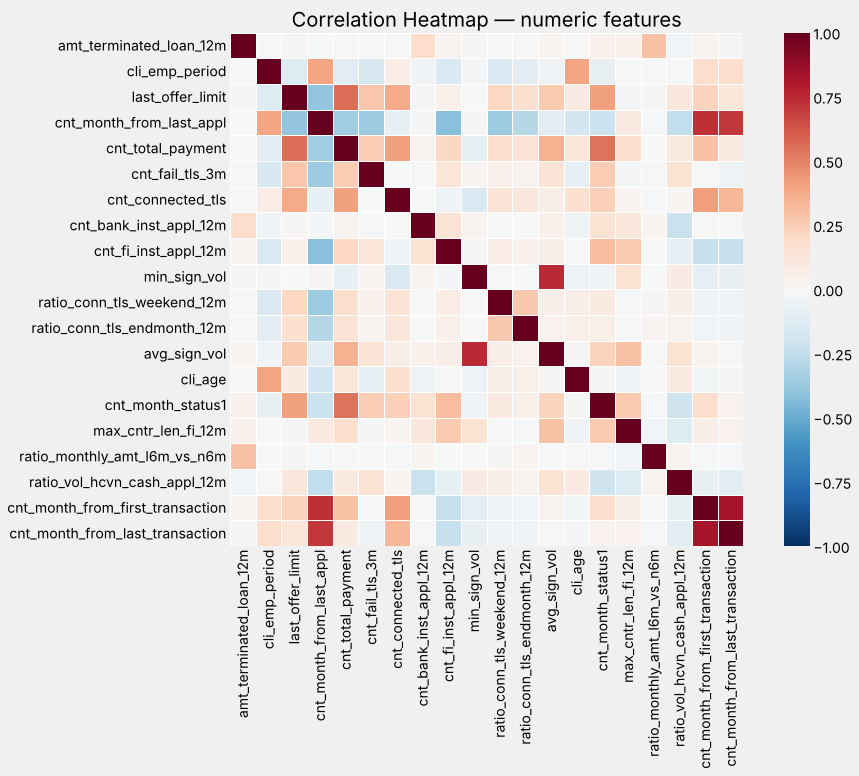

,feature_1,feature_2,corr
3,cnt_month_from_first_transaction,cnt_month_from_last_transaction,0.84
2,min_sign_vol,avg_sign_vol,0.75
0,cnt_month_from_last_appl,cnt_month_from_first_transaction,0.73
1,cnt_month_from_last_appl,cnt_month_from_last_transaction,0.71


In [2]:
num_cols = C.NUM_CONT_COLS + [c for c in C.HIGH_MISSING_COLS if c != "f_appointment_3m"]
corr, pairs = strong_correlations(df, num_cols, threshold=0.7)
fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(corr, cmap="RdBu_r", vmin=-1, vmax=1, square=True, linewidths=0.5, ax=ax)
ax.set_title("Correlation Heatmap — numeric features")
fig.tight_layout()
fig.savefig(FIG / "interaction_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()
pairs.sort_values("corr", key=abs, ascending=False)

## 2. Feature × Treatment interaction

In [3]:
features = C.NUM_CONT_COLS + C.NUM_CAT_COLS + C.NOMINAL_COLS[1:] + C.ORDINAL_COLS
strength = interaction_strength(df, features)
strength.round(3)

,feature,n_segments,uplift_cash_range,uplift_cash_wstd,uplift_card_range,uplift_card_wstd,interaction_score
0,cnt_month_from_last_appl,10,4.942,1.499,1.032,0.295,1.794
1,cnt_month_status1,10,3.749,1.180,1.742,0.465,1.646
2,last_offer_limit,10,3.750,1.063,1.619,0.556,1.620
3,cnt_fi_inst_appl_12m,3,4.479,1.385,0.780,0.233,1.618
4,cnt_noinsurance_loan_24m,2,15.968,1.302,3.540,0.289,1.591
5,cnt_total_payment,10,3.607,1.194,0.978,0.331,1.526
6,cnt_fail_tls_3m,7,3.404,0.966,1.186,0.341,1.307
7,cli_emp_period,10,3.497,0.986,0.613,0.237,1.223
8,cnt_report_institution_12m,3,4.019,1.071,0.441,0.102,1.174
9,avg_sign_vol,10,3.257,0.920,0.886,0.251,1.171


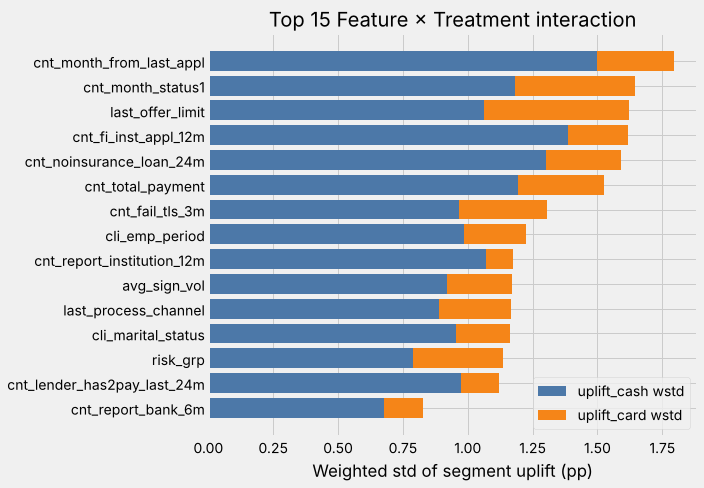

In [4]:
top = strength.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top["feature"], top["uplift_cash_wstd"], label="uplift_cash wstd", color="#4C78A8")
ax.barh(top["feature"], top["uplift_card_wstd"], left=top["uplift_cash_wstd"], label="uplift_card wstd", color="#F58518")
ax.set_xlabel("Weighted std of segment uplift (pp)")
ax.set_title("Top 15 Feature × Treatment interaction")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "interaction_feature_treatment.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
segments = {
    "age_bucket": df["age_bucket"],
    "risk_grp": df["risk_grp"],
    "payment_decile": df["payment_decile"],
    "termination_bucket": df["termination_bucket"],
    "last_appl_decile": pd.qcut(df["cnt_month_from_last_appl"], 10, duplicates="drop"),
}
for name, seg in segments.items():
    print(name)
    display(segment_uplift(df.assign(_seg=seg), "_seg").round(2))

age_bucket


,n_cash,n_card,uplift_cash,uplift_card
_seg,,,,
<25,9410,7914,1.04,0.47
25-35,28090,22790,0.61,0.08
35-45,24233,19563,0.82,0.24
45-55,12255,9807,0.71,0.33
55+,1624,1306,1.24,0.24


risk_grp


,n_cash,n_card,uplift_cash,uplift_card
_seg,,,,
A,5209,4344,2.42,1.07
B,6130,5101,2.30,0.66
C,20743,16436,0.86,0.47
D,17885,14189,0.67,-0.00
E,25328,21053,-0.07,-0.04
F,42,27,-4.23,-1.06
G,8,5,0.00,0.00
H,2,3,-33.33,0.00
I,1,3,0.00,33.33


payment_decile


,n_cash,n_card,uplift_cash,uplift_card
_seg,,,,
D1,12463,9914,0.10,0.01
D2,6268,4967,-0.10,0.02
D3,5627,4502,0.00,-0.08
D4,7877,6375,0.02,-0.12
D5,6805,5505,0.38,0.13
D6,6791,5543,-0.22,0.28
D7,7650,6292,0.83,0.00
D8,7208,5968,0.84,0.80
D9,7418,6125,2.79,0.35


termination_bucket


,n_cash,n_card,uplift_cash,uplift_card
_seg,,,,
0,42374,35374,1.17,0.25
1,9423,7774,1.38,0.56
2,1221,1017,0.43,-0.60
3,199,144,3.12,4.00
4+,148,112,10.28,-1.86


last_appl_decile


,n_cash,n_card,uplift_cash,uplift_card
_seg,,,,
"(-0.001, 6.0]",8519,7236,4.43,0.74
"(6.0, 11.0]",6587,5514,2.03,0.33
"(11.0, 19.0]",7871,6780,2.03,-0.02
"(19.0, 28.0]",6938,5725,0.59,-0.29
"(28.0, 40.0]",7234,6109,0.18,0.49
"(40.0, 55.0]",7942,6303,-0.04,0.26
"(55.0, 69.0]",7314,5834,0.18,-0.09
"(69.0, 84.0]",7861,6241,-0.52,-0.03
"(84.0, 102.0]",7724,6002,0.03,0.02


## 3. Two-way interaction: Risk Group × Age Bucket

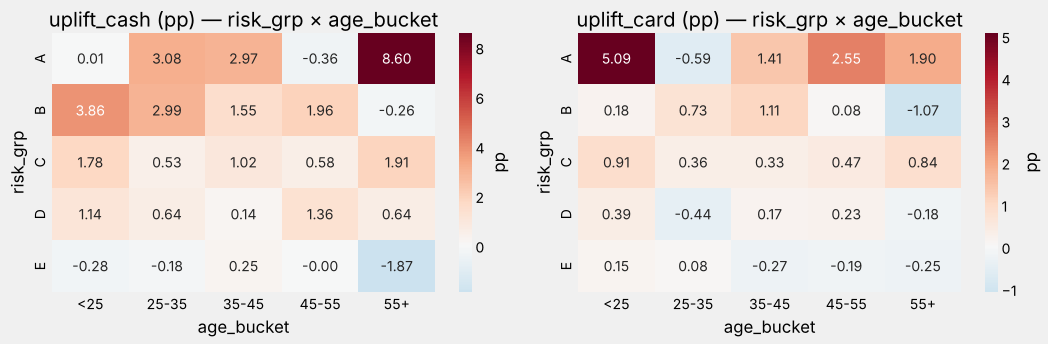

In [6]:
main = df[df["risk_grp"].isin(list("ABCDE"))]
grid = {}
for target in ["uplift_cash", "uplift_card"]:
    grid[target] = (
        main.groupby("risk_grp")
        .apply(lambda g: segment_uplift(g, "age_bucket")[target], include_groups=False)
        .round(2)
    )
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, (target, table) in zip(axes, grid.items()):
    sns.heatmap(table, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax, cbar_kws={"label": "pp"})
    ax.set_title(f"{target} (pp) — risk_grp × age_bucket")
fig.tight_layout()
fig.savefig(FIG / "interaction_risk_age.png", dpi=150, bbox_inches="tight")
plt.show()

## 4. Interaction design matrix cho INT_RF

INT_RF học một Random Forest duy nhất trên `[X, W, X·W]`, sau đó dự đoán hai kịch bản `W=1` và `W=0`:

`uplift(x) = P̂(y=1 | x, W=1) − P̂(y=1 | x, W=0)`

In [7]:
X, W, y_cash, y_card, feat_cols = load_model_data()
X_aug = interaction_matrix(X, (W == 1).astype(int))
pd.Series({"X": X.shape[1], "W": 1, "X·W": X.shape[1], "X_aug": X_aug.shape[1]}, name="n_columns")

X         62
W          1
X·W       62
X_aug    125
Name: n_columns, dtype: int64